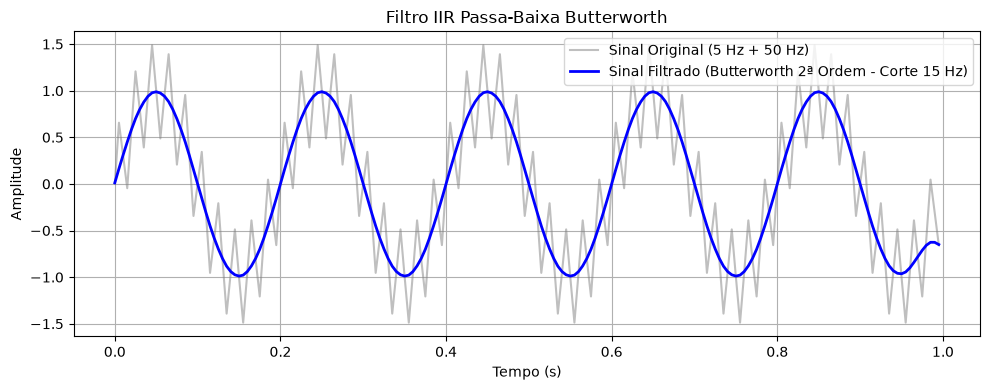

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# --- 1. Parâmetros do Sinal e do Filtro ---
fs = 200.0  # Frequência de amostragem em Hz
t = np.arange(0, 1.0, 1.0 / fs)  # Vetor de tempo de 1 segundo

# Sinal original: soma de uma senoide de 5 Hz (desejada) e 50 Hz (ruído)
f_baixa = 5.0
f_alta = 50.0
sinal_original = np.sin(2 * np.pi * f_baixa * t) + 0.5 * np.sin(2 * np.pi * f_alta * t)

# --- 2. Projeto do Filtro Butterworth de 2ª Ordem ---
ordem = 2
frequencia_corte = 15.0  # Frequência de corte em Hz

# Usando 'sos' (Second-Order Sections) para maior estabilidade numérica
sos = signal.butter(N=ordem, Wn=frequencia_corte, btype='lowpass', analog=False, fs=fs, output='sos')

# --- 3. Aplicação do Filtro ---
# sosfiltfilt aplica o filtro para frente e para trás, eliminando o atraso de fase
sinal_filtrado = signal.sosfiltfilt(sos, sinal_original)

# --- 4. Plotagem dos Resultados ---
plt.figure(figsize=(10, 4))
plt.plot(t, sinal_original, label='Sinal Original (5 Hz + 50 Hz)', alpha=0.5, color='gray')
plt.plot(t, sinal_filtrado, label='Sinal Filtrado (Butterworth 2ª Ordem - Corte 15 Hz)', color='blue', linewidth=2)
plt.title('Filtro IIR Passa-Baixa Butterworth')
plt.xlabel('Tempo (s)')
plt.ylabel('Amplitude')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()
